In [1]:
#normalize list, Frobenius norm
def normalize_roi (roi_intensities):
    roi_normalized = roi_intensities/np.linalg.norm (roi_intensities)
    return (roi_normalized)

In [2]:
def roi_stats(roi_normalized):
    roi_mean = np.mean(roi_normalized)
    
    roi_variance = np.var(roi_normalized)
    
    roi_histogram = np.histogram(roi_normalized) #check for different bin count methods
    return (roi_mean, roi_variance, roi_histogram)

In [3]:
def rayleigh_stats(roi_average, roi_variance):
    rayleigh_mu = 0
    
    rayleigh_sigmaMean = roi_average/np.sqrt(np.pi/2) #calculated from avg
    
    rayleigh_sigmaVar = np.sqrt(2*roi_variance/(4-np.pi)) #calculated from var
    
    return (rayleigh_mu, rayleigh_sigmaMean, rayleigh_sigmaVar)

In [4]:
def gauss_stats(roi_average, roi_variance):
    gauss_mu = roi_average
    
    gauss_sigma = np.sqrt(roi_variance)
    
    return (gauss_mu, gauss_sigma)

In [9]:
import numpy as np
def standard_error (score, pred_score, n_pairs):   
    s = np.sqrt(np.sum(np.square(score-pred_score))/(n_pairs-2))
    return (s)

y1 = [1, 2, 1.3, 3.75, 2.25]
y2 = [1.210, 1.635, 2.060, 2.485, 2.910]
y1 = np.array(y1)
y2 = np.array(y2)

standard_error(y1,y2,5)

0.96449468635135571

1
[-0.01554417 -0.00077528]
[-170.18366941   -8.4880777 ]


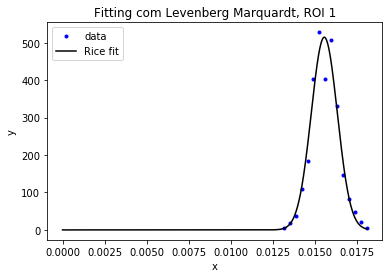

2
[ 0.01585028 -0.00079379]
[ 120.40666411   -6.03005272]


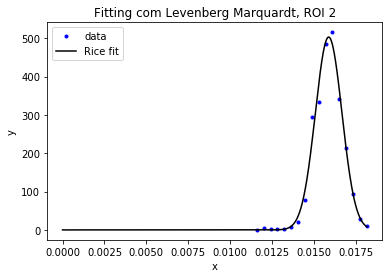

3
[-0.02033142 -0.00080506]
[-191.64008502   -7.58832173]


C:\Users\Yuri\Anaconda2\lib\site-packages\ipykernel\__main__.py:19: RuntimeWarning: invalid value encountered in multiply


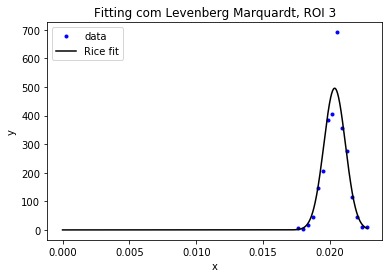

4
[ 0.01521396 -0.00082958]
[ 116.83274228   -6.37057922]


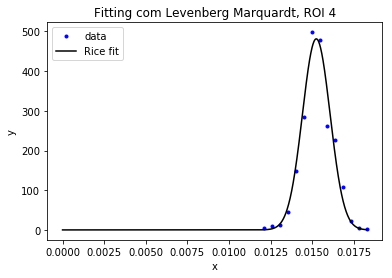

5
[ 0.0166525  -0.00098428]
[ 111.94978159   -6.61702477]


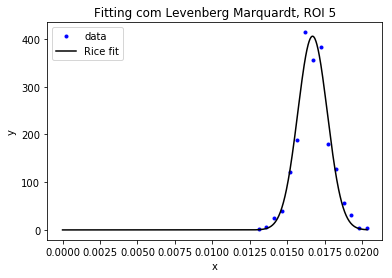

6
[ 0.02002178 -0.00108672]
[ 110.2845162    -5.98589211]


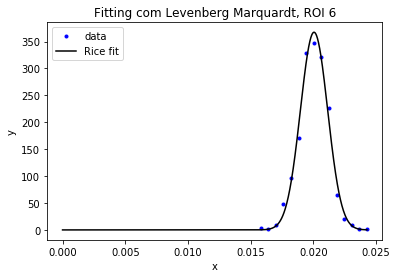

7
[ 0.02152229 -0.00104257]
[ 111.20704624   -5.38703321]


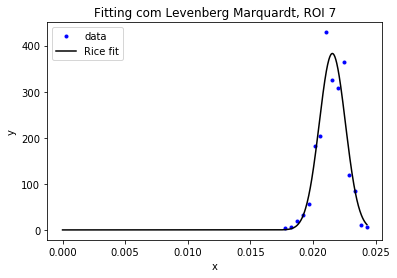

8


IOError: gord2_15T (8).csv not found.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import scipy.special as sci
from sklearn.metrics import r2_score
from scipy.stats import rice, chisquare

#import csv file for ROI pixel list
def import_roi (roi_file):
    roi = np.genfromtxt(roi_file, delimiter=',')
    roi_intensities = roi[1:len(roi),3] #deixa somente as intensidades
    return (roi_intensities)
#normalize list, Frobenius norm
def normalize_roi (roi_intensities):
    roi_normalized = roi_intensities/np.linalg.norm (roi_intensities)
    return (roi_normalized, np.linalg.norm (roi_intensities))
#define pdf for Rice (probability distribution function)
def func(x, v, s):
    f = (x/s**2)*np.exp(-1*(x**2+v**2)/(2*s**2))*sci.iv(0,x*v/(s**2))
    return f

for i in range(1,48):  #number of ROIs to be analyzed
    print i
    a = import_roi('gord2_15T (%d).csv' % i)
    #data prep
    nbins = np.max(a)-np.min(a)
    a,norm = normalize_roi(a)

    #fitting levenberg Marquardt
    #data prep
    [a_hist, a_bins] = np.histogram(a, bins='doane', density=True)
    xdata = a_bins[0:len(a_bins)-1]
    ydata = a_hist
    #fit
    popt, pcov = curve_fit(func, xdata, ydata)
    print popt #, np.sqrt(np.diag(pcov))
    print popt*norm
    x_verif = np.linspace(0, xdata.max(), 1000)
    y_verif = func(x_verif, popt[0], popt[1])
    #plot
    plt.plot(xdata, ydata, 'b.', label='data')
    plt.plot(x_verif, y_verif, 'k', label='Rice fit')
    plt.title("Fitting com Levenberg Marquardt, ROI %d" % i)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.show()

'''
    #fitting rice.fit
    #fit
    shape, loc, scale = rice.fit(a)
    print shape, loc*norm, scale*norm
    y2_verif = rice.pdf(x_verif, shape, loc, scale)
    #plot
    fig, ax = plt.subplots(1, 1)
    plt.plot(xdata, ydata, 'b.', label='data')
    plt.plot(x_verif, y2_verif, 'k', label='Rice fit')
    plt.title("Fitting com rice.fit, ROI %d" %i)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.show()

    #correlation stats
    print r2_score(ydata, func(xdata, popt[0], popt[1]))
    print chisquare(ydata, func(xdata, popt[0], popt[1]))
'''

In [6]:
#célula de teste

a = import_roi('s2e3.csv')
a_norm = normalize_roi(a)
[an_mean, an_var, an_hist] = roi_stats(a_norm)
[an_ray_mu, an_ray_sigmaMean, an_ray_sigmaVar]  = rayleigh_stats(an_mean, an_var)

print an_mean, an_var, an_ray_sigma1, an_ray_sigma2, an_ray_mu

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()